<a href="https://colab.research.google.com/github/Safuraali/sem_7/blob/main/WEEK11_13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Linear Model MSE: 0.5333715987875559
Polynomial Model MSE: 0.29394682964830204


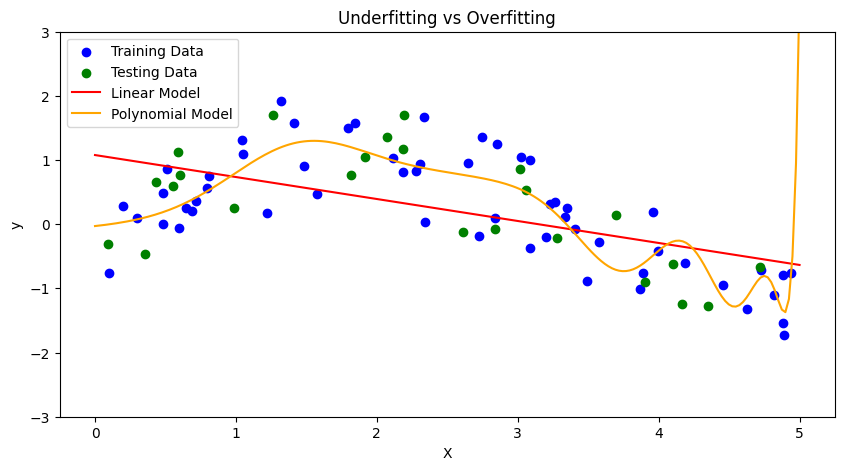

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
# Generate data
np.random.seed(0)
X = np.sort(5 * np.random.rand(80, 1), axis=0)
y = np.sin(X).ravel() + np.random.normal(0, 0.5, 80)
# Split data
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.3, random_state=42)
# Linear Regression (Underfitting)
linear = LinearRegression()
linear.fit(X_train, y_train)
# Polynomial Regression (Overfitting)
poly = make_pipeline(PolynomialFeatures(degree=20),LinearRegression())
poly.fit(X_train, y_train)
# Predictions
y_linear = linear.predict(X_test)
y_poly = poly.predict(X_test)
# Calculate errors
print("Linear Model MSE:", mean_squared_error(y_test, y_linear))
print("Polynomial Model MSE:", mean_squared_error(y_test, y_poly))
# Plot results
X_plot = np.linspace(0, 5, 200).reshape(-1, 1)
plt.figure(figsize=(10, 5))
plt.scatter(X_train, y_train, color='blue', label='Training Data')
plt.scatter(X_test, y_test, color='green', label='Testing Data')
plt.plot(X_plot, linear.predict(X_plot), color='red', label='Linear Model')
plt.plot(X_plot, poly.predict(X_plot),color='orange', label='Polynomial Model')
plt.title("Underfitting vs Overfitting")
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.ylim(-3, 3)
plt.show()

Linear Data Accuracy: 0.94


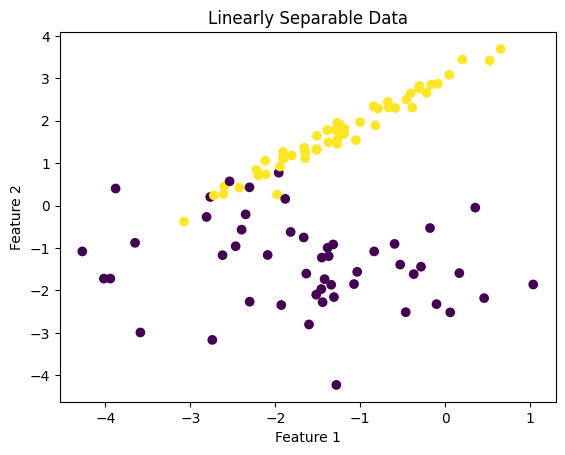

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
# Generate linearly separable data
X_linear, y_linear = make_classification(
    n_samples=100,
    n_features=2,
    n_redundant=0,
    n_informative=2,
    n_clusters_per_class=1,
    random_state=4,
    class_sep=1.5)
# Train Logistic Regression
model1 = LogisticRegression()
model1.fit(X_linear, y_linear)
# Prediction
pred1 = model1.predict(X_linear)
print("Linear Data Accuracy:", accuracy_score(y_linear, pred1))
# Plot data
plt.scatter(X_linear[:, 0], X_linear[:, 1],  c=y_linear, cmap='viridis')
plt.title("Linearly Separable Data")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

Non-linear Data Accuracy: 0.49


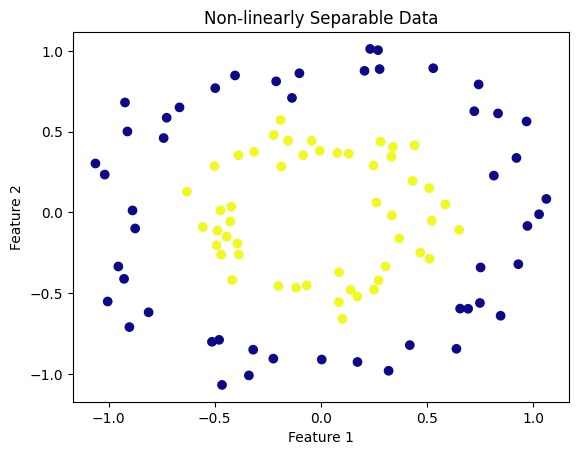

In [ ]:
from sklearn.datasets import make_circles
# Generate circular data
X_nonlinear, y_nonlinear = make_circles(
    n_samples=100,
    noise=0.1,
    factor=0.5,
    random_state=1)
# Train Logistic Regression
model2 = LogisticRegression()
model2.fit(X_nonlinear, y_nonlinear)
# Prediction
pred2 = model2.predict(X_nonlinear)
print("Non-linear Data Accuracy:", accuracy_score(y_nonlinear, pred2))
# Plot data
plt.scatter(X_nonlinear[:, 0], X_nonlinear[:, 1],c=y_nonlinear, cmap='plasma')
plt.title("Non-linearly Separable Data")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
# Create simulated churn data
np.random.seed(0)
churn_data = pd.DataFrame({'MonthlyCharges': np.random.uniform(20, 100, 200),'DataUsageGB': np.random.uniform(10, 80, 200),
    'ContractYears': np.random.randint(1, 4, 200),'Churn': np.random.choice([0, 1], 200, p=[0.7, 0.3])})
# Separate features and target
X = churn_data.drop('Churn', axis=1)
y = churn_data['Churn']
print("Original Data:")
print(churn_data.head())
# Activity 1.2: Train-Test Split (70%-30%)
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.3, random_state=42)
print("\nTrain-Test Split:")
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)
# Activity 1.3: Train-Validation-Test Split (60%-20%-20%)
# First split: 80% training + validation, 20% testing
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# Second split: 60% training, 20% validation
X_train, X_val, y_train, y_val = train_test_split( X_temp, y_temp, test_size=0.25, random_state=42)
print("\nTrain-Validation-Test Split:")
print("Training Data:", X_train.shape)
print("Validation Data:", X_val.shape)
print("Testing Data:", X_test.shape)

Original Data:
   MonthlyCharges  DataUsageGB  ContractYears  Churn
0       63.905080    31.825712              2      0
1       77.215149    58.744044              1      0
2       68.221070    36.442629              2      0
3       63.590655    22.572257              1      1
4       53.892384    11.727511              3      0

Train-Test Split:
Training Data: (140, 3)
Testing Data: (60, 3)

Train-Validation-Test Split:
Training Data: (120, 3)
Validation Data: (40, 3)
Testing Data: (40, 3)


In [ ]:
import pandas as pd
from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import LogisticRegression
# Separate features and target
X = churn_data.drop('Churn', axis=1)
y = churn_data['Churn']
# Create Logistic Regression model
model = LogisticRegression(max_iter=1000)
# Apply 5-Fold Cross Validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)
# Calculate accuracy for each folD
scores = cross_val_score(model, X, y, cv=kf, scoring='accuracy')
# Print accuracy of each fold
for i, score in enumerate(scores):
    print("Fold", i+1, "Accuracy:", score)
# Print average accuracy
print("Average Accuracy:", scores.mean())

Fold 1 Accuracy: 0.625
Fold 2 Accuracy: 0.7
Fold 3 Accuracy: 0.85
Fold 4 Accuracy: 0.825
Fold 5 Accuracy: 0.7
Average Accuracy: 0.74


In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
# True labels (0 = Not Spam, 1 = Spam)
y_true_spam = np.array([0, 0, 1, 0, 1, 1, 0, 0, 1, 0,
                        1, 0, 0, 1, 1, 0, 1, 0, 1, 0])
# Predicted labels
y_pred_spam = np.array([0, 0, 1, 0, 0, 1, 0, 1, 1, 0,
                        1, 0, 0, 1, 0, 0, 1, 0, 1, 0])
print("True Labels:", y_true_spam)
print("Predicted Labels:", y_pred_spam)
# Calculate accuracy
accuracy = accuracy_score(y_true_spam, y_pred_spam)
print("Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

True Labels: [0 0 1 0 1 1 0 0 1 0 1 0 0 1 1 0 1 0 1 0]
Predicted Labels: [0 0 1 0 0 1 0 1 1 0 1 0 0 1 0 0 1 0 1 0]
Accuracy: 0.85
Accuracy Percentage: 85.0 %


Confusion Matrix:
 [[10  1]
 [ 2  7]]
True Positive: 7
True Negative: 10
False Positive: 1
False Negative: 2


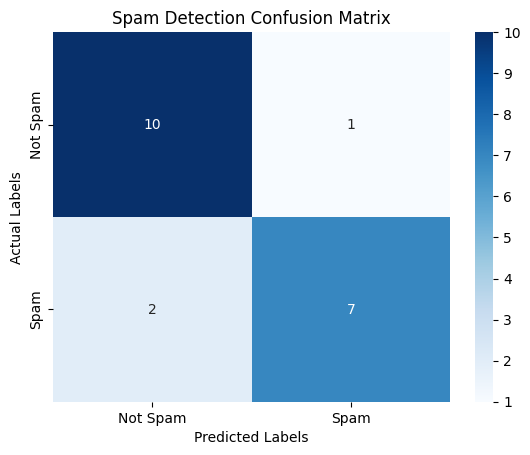

In [ ]:
# Create confusion matrix
cm = confusion_matrix(y_true_spam, y_pred_spam)
print("Confusion Matrix:\n", cm)
# Identify TP, TN, FP, FN
TN, FP, FN, TP = cm.ravel()
print("True Positive:", TP)
print("True Negative:", TN)
print("False Positive:", FP)
print("False Negative:", FN)
# Display confusion matrix
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Spam', 'Spam'],
            yticklabels=['Not Spam', 'Spam'])
plt.xlabel("Predicted Labels")
plt.ylabel("Actual Labels")
plt.title("Spam Detection Confusion Matrix")
plt.show()